#Estudo de denuncias de personas desaparecidas en España

Datos: Gobieno de España - https://datos.gob.es/es/catalogo/a13002908-personas-desaparecidas-por-ano-de-denuncia-y-estado

##FASE 1 : Conocer los datos

Importar las librerías

In [24]:
import pandas as pd
import matplotlib.pyplot as plt

In [25]:
import os
import matplotlib.pyplot as plt

os.makedirs("graficos", exist_ok=True)

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "#F7F9FC",
    "axes.edgecolor": "#D9E1F2",
    "axes.labelcolor": "#263238",
    "text.color": "#263238",
    "axes.titleweight": "bold",
    "axes.titlesize": 16,
    "axes.labelsize": 11,
    "xtick.color": "#455A64",
    "ytick.color": "#455A64",
    "font.family": "sans-serif",
    "grid.color": "#D9E1F2",
    "grid.alpha": 0.7,
})

Subir, cargar el CSV y ver las primeras 5 filas

In [26]:
df = pd.read_csv("personas-desaparecidas.csv",
                 sep=";",
                 encoding="cp1252")

df.head()

,Año,Concepto,Tipo territorio,Código territorio,Territorio,Valor,Unidad,Estado dato
0,2010,Denuncias de personas desaparecidas activas ma...,Otros,NaN,NaN,3,Número,NaN
1,2010,Denuncias de personas desaparecidas activas fe...,Otros,NaN,NaN,1,Número,NaN
2,2010,Denuncias de personas desaparecidas activas en...,Otros,NaN,NaN,1,Número,NaN
3,2010,Denuncias de personas desaparecidas de menores...,Otros,NaN,NaN,0,Número,NaN
4,2010,Denuncias de personas desaparecidas cesadas en...,Otros,NaN,NaN,4,Número,NaN


Averiguar cuántas filas y columnas tiene

In [27]:
print("Filas:", df.shape[0])
print("Columnas:", df.shape[1])

Filas: 144
Columnas: 8


Identificar qué información contiene cada columna

In [28]:
print(df.columns.tolist())

['Año', 'Concepto', 'Tipo territorio', 'Código territorio', 'Territorio', 'Valor', 'Unidad', 'Estado dato']


# Las columnas significan:
- Año: año en que se presentó la denuncia.
- Concepto: categoría de la denuncia, según su estado y el sexo registrado.
- Tipo territorio: tipo de ámbito territorial indicado. - SIN DATOS
- Código territorio: código territorial, si consta.- SIN DATOS
- Territorio: nombre o valor territorial, si consta.- SIN DATOS
- Valor: número de denuncias.
- Unidad: unidad de medida; en este archivo, “Número”.
- Estado dato: campo de estado del dato.

Comprobar los tipos de datos

In [29]:
df.dtypes

,0
Año,int64
Concepto,object
Tipo territorio,object
Código territorio,float64
Territorio,float64
Valor,object
Unidad,object
Estado dato,float64


Limpieza: Revisar valores nulos y duplicados

In [30]:
print("Valores nulos por columna:")
display(df.isnull().sum())

print("Filas duplicadas:", df.duplicated().sum())

Valores nulos por columna:


,0
Año,0
Concepto,0
Tipo territorio,0
Código territorio,144
Territorio,144
Valor,0
Unidad,0
Estado dato,144


Filas duplicadas: 0


Conclusión fase 01:

Qué información contiene este dataset?

Recuentos de denuncias por desaparición en España y están organizados por año de denuncia y concepto(denuncias activas, cesadas y de menores ausentados), además de separar por sexo masculino, femenino o desconocido.

Cuántos registros y variables tiene?
- 144 registros
- 8 variables

Hay datos incompletos o problemas de calidad?
Sí...Hay campos vacíos en las columnas territoriales así que no hay datos por comunidad o provincias.

Qué columna o variable te parece más interesante?
Concepto (porque permite comparar el estado de las denuncias) y el sexo registrado.

#FASE 2 : Investiga y haz preguntas

Preparar los datos (como hay guiones, hay que convertir en valores ausentes)

In [31]:
df["Valor_num"] = pd.to_numeric(df["Valor"], errors="coerce")

print("Valores que no se pudieron convertir:")
display(df[df["Valor_num"].isna()][["Año", "Concepto", "Valor"]])

Valores que no se pudieron convertir:


,Año,Concepto,Valor
143,2025,Denuncias de personas desaparecidas de menores...,-


Crear una columna para agrupar las denuncias activas y cesadas

In [32]:
df["Estado"] = df["Concepto"].str.extract(r"(activas|cesadas)", expand=False)

df[["Año", "Concepto", "Valor_num", "Estado"]].head(10)

,Año,Concepto,Valor_num,Estado
0,2010,Denuncias de personas desaparecidas activas ma...,3.0,activas
1,2010,Denuncias de personas desaparecidas activas fe...,1.0,activas
2,2010,Denuncias de personas desaparecidas activas en...,1.0,activas
3,2010,Denuncias de personas desaparecidas de menores...,0.0,NaN
4,2010,Denuncias de personas desaparecidas cesadas en...,4.0,cesadas
5,2010,Denuncias de personas desaparecidas de menores...,0.0,NaN
6,2010,Denuncias de personas desaparecidas cesadas ma...,167.0,cesadas
7,2010,Denuncias de personas desaparecidas cesadas fe...,120.0,cesadas
8,2010,Denuncias de personas desaparecidas de menores...,0.0,NaN
9,2011,Denuncias de personas desaparecidas activas ma...,3.0,activas


Cómo cambió el número de denuncias activas y cesadas por año?

In [42]:
por_ano_estado = (
    df[df["Estado"].notna()]
    .groupby(["Año", "Estado"])["Valor_num"]
    .sum()
    .unstack()
)

display(por_ano_estado)

Estado,activas,cesadas
Año,,
2010,5.0,291.0
2011,6.0,1077.0
2012,7.0,1800.0
2013,7.0,1787.0
2014,4.0,1923.0
2015,6.0,2094.0
2016,8.0,2265.0
2017,7.0,2410.0
2018,7.0,2724.0


Cómo se distribuyen las denuncias activas y cesadas según el sexo registrado?

In [34]:
por_estado_sexo = (
    df[df["Estado"].notna()]
    .assign(
        Sexo=df["Concepto"].str.extract(
            r"(masculinas|femeninas|se desconoce el sexo)", expand=False
        )
    )
    .groupby(["Estado", "Sexo"])["Valor_num"]
    .sum()
    .unstack()
)

display(por_estado_sexo.astype("Int64"))

Sexo,femeninas,masculinas,se desconoce el sexo
Estado,,,
activas,180,281,2
cesadas,17952,20116,93


Qué sexo registrado tiene más denuncias activas cada año?

In [35]:
activas = df[df["Estado"] == "activas"].copy()

activas["Sexo"] = activas["Concepto"].str.extract(
    r"(masculinas|femeninas|se desconoce el sexo)", expand=False
)

activas_por_ano_sexo = (
    activas.groupby(["Año", "Sexo"])["Valor_num"]
    .sum()
    .unstack()
)

display(activas_por_ano_sexo.astype("Int64"))

Sexo,femeninas,masculinas,se desconoce el sexo
Año,,,
2010,1,3,1
2011,2,3,1
2012,3,4,0
2013,5,2,0
2014,4,0,0
2015,3,3,0
2016,5,3,0
2017,2,5,0
2018,5,2,0


Cuántas denuncias de menores ausentados aparecen cada año?

In [36]:
menores_ausentados = df[
    df["Concepto"].str.contains("menores ausentados", case=False, na=False)
]

tabla = (
    menores_ausentados
    .groupby("Año")["Valor_num"]
    .sum()
    .to_frame("Denuncias de menores ausentados")
)

display(tabla.astype("Int64"))

,Denuncias de menores ausentados
Año,
2010,0
2011,0
2012,0
2013,0
2014,0
2015,2
2016,0
2017,0
2018,1


#FASE 3: Visualizar mis descubrimientos

**Denuncias activas y cesadas por año**

El gráfico compara cuántas denuncias de cada año constan como activas o cesadas. Las denúncias se pasan a "cesadas" cuando la persona o sus restos mortales son encontrados.
Analizando el gráfico, podemos concluir que, felizmente, el número de denúncias cesadas/resueltas é mucho más grande que lo de nuevas denúncias.

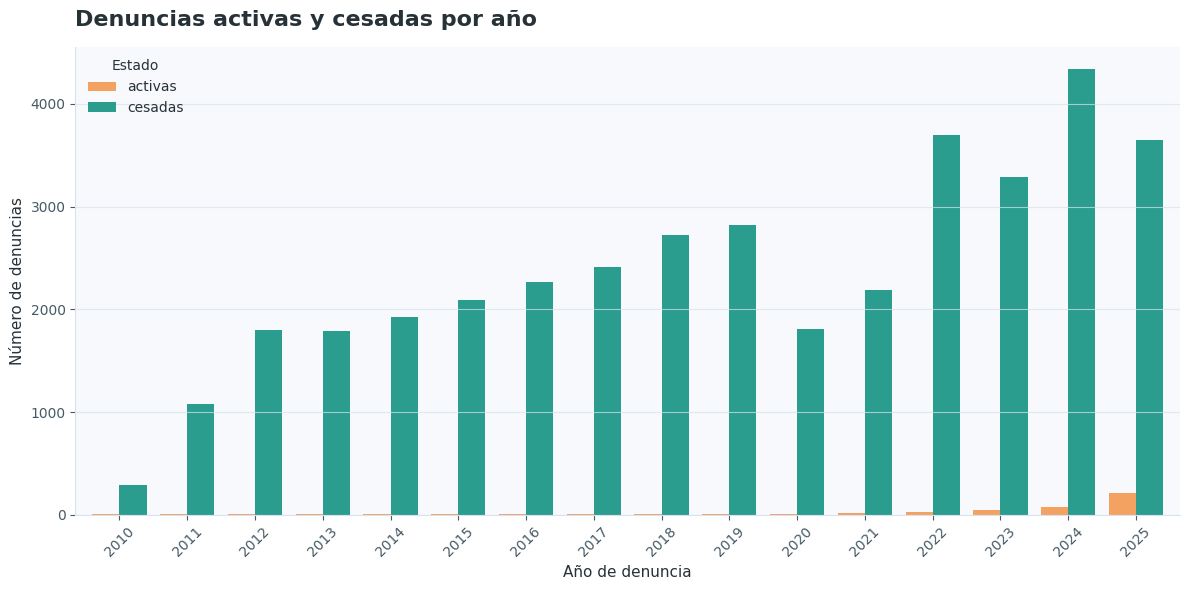

In [43]:
fig, ax = plt.subplots(figsize=(12, 6))

por_ano_estado.plot(
    kind="bar",
    ax=ax,
    color=["#F4A261", "#2A9D8F"],
    width=0.8
)

ax.set_title("Denuncias activas y cesadas por año", loc="left", pad=15)
ax.set_xlabel("Año de denuncia")
ax.set_ylabel("Número de denuncias")
ax.legend(title="Estado", frameon=False)
ax.grid(axis="y")
ax.grid(axis="x", visible=False)
ax.spines[["top", "right"]].set_visible(False)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("graficos/01_denuncias_por_estado_y_ano.png", dpi=200, bbox_inches="tight")
plt.show()

**Denuncias por sexo registrado**


En este gráfico, podemos mirar visualmente la cantidad de denuncias por sexo, dividido en três partes: femeninas, masculinas y sin genêro definido.
Aunque el número de denñuncias del sexo masculino sea más grande, no háuna gran diferencia comparado con la de las mujeres, apenas 5.9% de diferencia.

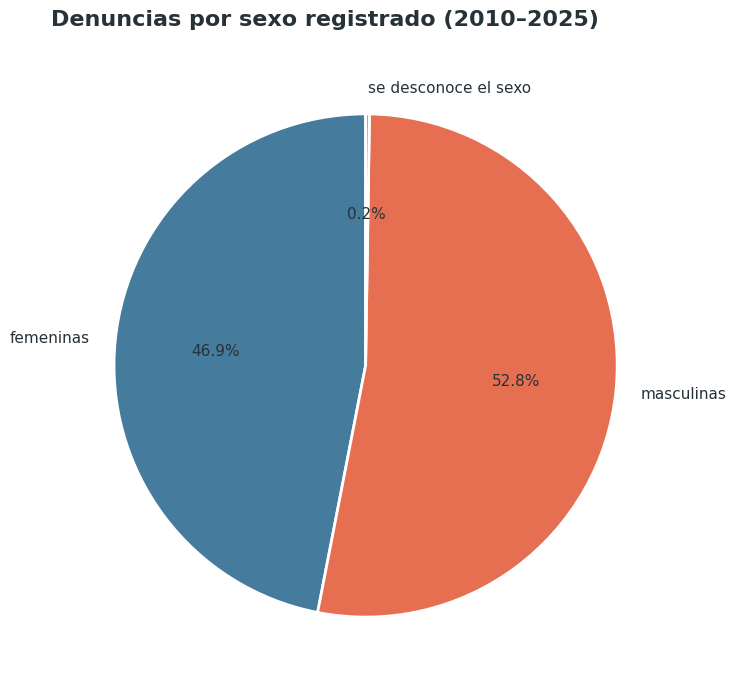

In [44]:
colores = ["#457B9D", "#E76F51", "#A8A8A8"]

fig, ax = plt.subplots(figsize=(8, 7))

por_sexo.plot(
    kind="pie",
    ax=ax,
    colors=colores,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"edgecolor": "white", "linewidth": 2},
    textprops={"fontsize": 11}
)

ax.set_title("Denuncias por sexo registrado (2010–2025)", loc="left", pad=18)
ax.set_ylabel("")
plt.tight_layout()
plt.savefig("graficos/02_denuncias_por_sexo.png", dpi=200, bbox_inches="tight")
plt.show()

**Evolución anual del total de denuncias:**

Aquí podemos mirar la sima anual de las denúncias activas y cesadas por año. Aunque ha tenido una bajda en 2020, las denuncias siguen en cresciente desde 2010. El número puede parecer bajo, pero no podemos dejar de preocuparnos por el crescimiento,

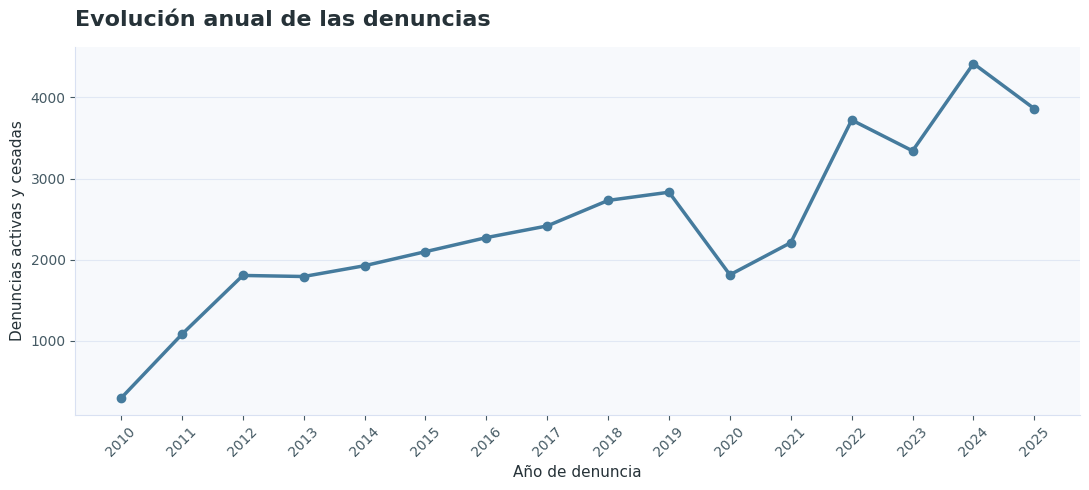

In [45]:
fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    total_por_ano.index,
    total_por_ano.values,
    color="#457B9D",
    marker="o",
    markersize=6,
    linewidth=2.5
)

ax.set_title("Evolución anual de las denuncias", loc="left", pad=15)
ax.set_xlabel("Año de denuncia")
ax.set_ylabel("Denuncias activas y cesadas")
ax.grid(axis="y")
ax.grid(axis="x", visible=False)
ax.spines[["top", "right"]].set_visible(False)
plt.xticks(total_por_ano.index, rotation=45)
plt.tight_layout()
plt.savefig("graficos/03_evolucion_anual.png", dpi=200, bbox_inches="tight")
plt.show()


**Proporción activa por año**

Aquí podemos analizar la cantidad de denúnicas que siguen activas cada año. entre 2011 y 2022, el número seguía igual, hasta que en 2024 tuvo su curva de crescimiento muy alta.

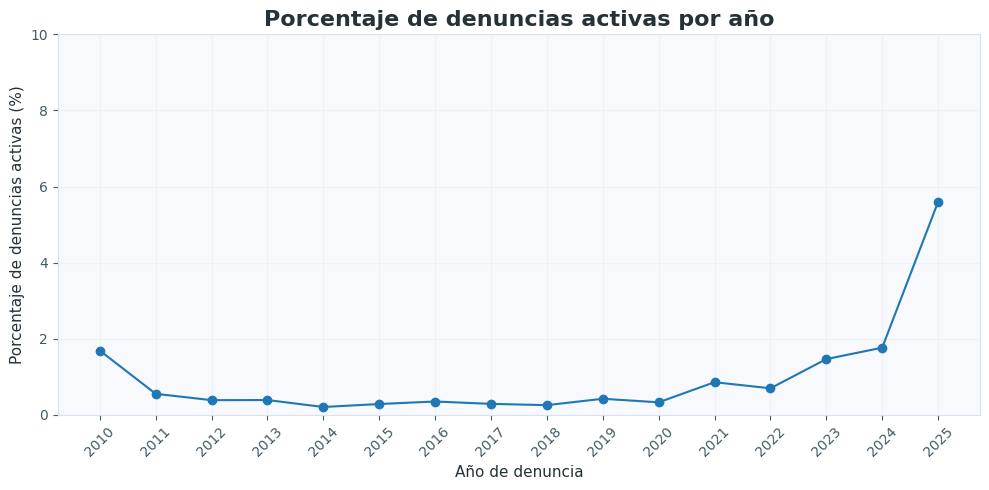

In [40]:
fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    proporcion_activas.index,
    proporcion_activas.values,
    color="#E76F51",
    marker="o",
    markersize=6,
    linewidth=2.5
)

ax.set_title("Porcentaje de denuncias activas por año", loc="left", pad=15)
ax.set_xlabel("Año de denuncia")
ax.set_ylabel("Denuncias activas (%)")
ax.set_ylim(0, 100)
ax.grid(axis="y")
ax.grid(axis="x", visible=False)
ax.spines[["top", "right"]].set_visible(False)
plt.xticks(proporcion_activas.index, rotation=45)
plt.tight_layout()
plt.savefig("graficos/04_porcentaje_activas.png", dpi=200, bbox_inches="tight")
plt.show()

#FASE 4. Conclusiones

**¿Cuáles son los 3 descubrimientos más interesantes que has realizado?**
1. Que la cantidad de denuncias de hombres desaparecidos es un poco más grande que de las mujeres. En mi percepción, pensé que seria al revés.
2. Existen años que no han tenido denúncias
3. Que las denúncias cesadas no siempre traen una buena respuesta al denunciante.

**¿Qué resultado te ha sorprendido?**
La cantidad de denúncias al año. Me quedé contenta que es un número muy bajo.

**¿Has encontrado algún patrón o tendencia?**
Sí, que la cantidad de denúncias sube cada año

**¿Qué decisión podría tomar una empresa u organización utilizando esta información?**
La polícia puede usar estos datos para estudos e crear materiales de conscientización/ayuda.

*¿Qué otra información te gustaría tener para profundizar en el análisis?*
Me gustaria que la tabla tuviera la edad de las personas denunciadas y también la población.

In [46]:
import shutil
from google.colab import files

shutil.make_archive("graficos", "zip", "graficos")
files.download("graficos.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>